# Stochastic Timestamp Generator for Synthetic APT Attack Data

## Mathematical Model

We model attack steps as a **Poisson process** where inter-arrival times follow an exponential distribution:

$$\Delta t \sim \text{Exponential}(\lambda)$$

Sampling via inverse CDF:
$$\Delta t = \frac{-\ln(U)}{\lambda}, \quad U \sim \text{Uniform}(0,1)$$

Cumulative timeline:
$$T_k = T_{k-1} + \Delta t_k$$

Where $\lambda_{\text{technique}} \approx \frac{f_{\text{technique}}}{\bar{T}_{\text{dwell}}}$ with $\bar{T}_{\text{dwell}} \approx 11 \text{ days} = 950{,}400 \text{ seconds}$ (Mandiant).

## 1. Imports & Configuration

In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
from typing import List, Dict, Optional, Tuple
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
np.random.seed(42)

# Dwell time constant (Mandiant: median 11 days)
T_DWELL_SECONDS = 11 * 24 * 3600  # 950,400 seconds

print(f"Dwell time constant: {T_DWELL_SECONDS:,} seconds ({T_DWELL_SECONDS / 86400:.0f} days)")
print("Imports loaded successfully.")

Dwell time constant: 950,400 seconds (11 days)
Imports loaded successfully.


## 2. Lambda Dictionary — Estimated Event Rates per Technique

$\lambda_{\text{technique}} = \frac{f_{\text{technique}}}{\bar{T}_{\text{dwell}}}$ where $f$ = frequency from Mandiant data and $\bar{T}_{\text{dwell}} = 950{,}400$ seconds.

In [2]:
# ── Lambda dictionary: technique → λ (events/second) ──
# Derived from: λ = frequency(%) / T_dwell(seconds)

lambda_dict = {
    # Initial Access
    "Exploit Public-Facing Application":   0.222 / T_DWELL_SECONDS,  # 2.34e-7
    "Valid Accounts":                       0.208 / T_DWELL_SECONDS,  # 2.19e-7
    
    # Execution
    "Command and Scripting Interpreter":   0.509 / T_DWELL_SECONDS,  # 5.36e-7
    "JavaScript":                          0.016 / T_DWELL_SECONDS,  # 1.68e-8
    "Unix Shell":                          0.050 / T_DWELL_SECONDS,  # fallback estimate
    "Native API":                          0.050 / T_DWELL_SECONDS,  # fallback estimate
    
    # Persistence / Privilege Escalation
    "Exploitation for Privilege Escalation": 0.002 / T_DWELL_SECONDS,  # 2.11e-9
    "Create Account":                      0.030 / T_DWELL_SECONDS,  # fallback estimate
    
    # Discovery
    "File and Directory Discovery":        0.342 / T_DWELL_SECONDS,  # 3.60e-7
    "System Information Discovery":        0.316 / T_DWELL_SECONDS,  # 3.33e-7
    "System Owner/User Discovery":         0.225 / T_DWELL_SECONDS,  # 2.37e-7
    "Process Discovery":                   0.207 / T_DWELL_SECONDS,  # 2.18e-7
    "System Network Connections Discovery": 0.082 / T_DWELL_SECONDS, # 8.63e-8
    "Vulnerability Scanning":              0.005 / T_DWELL_SECONDS,  # 5.26e-9
    
    # Lateral Movement
    "Remote Services":                     0.353 / T_DWELL_SECONDS,  # 3.71e-7 (lateral)
    "Remote Services (initial)":           0.224 / T_DWELL_SECONDS,  # 2.36e-7
    "Exploitation of Remote Services":     0.002 / T_DWELL_SECONDS,  # 2.11e-9
    "SSH":                                 0.129 / T_DWELL_SECONDS,  # 1.36e-7
    
    # Command & Control / Staging
    "Ingress Tool Transfer":               0.249 / T_DWELL_SECONDS,  # 2.62e-7
    
    # Credential Access
    "Password Guessing":                   0.034 / T_DWELL_SECONDS,  # 3.58e-8
    
    # Defense Evasion
    "File Deletion":                       0.252 / T_DWELL_SECONDS,  # 2.65e-7
    "Disable/Modify Tools":                0.133 / T_DWELL_SECONDS,  # 1.40e-7
    "Indicator Removal from Tools":        0.133 / T_DWELL_SECONDS,  # same as Disable/Modify
    "Timestomp":                           0.050 / T_DWELL_SECONDS,  # fallback estimate
    "Match Legitimate Name or Location":   0.050 / T_DWELL_SECONDS,  # fallback estimate
    "Linux/Mac Permissions Mod":           0.050 / T_DWELL_SECONDS,  # fallback estimate
    "Network Sniffing":                    0.005 / T_DWELL_SECONDS,  # 5.26e-9
    
    # Collection
    "Data from Local System":              0.011 / T_DWELL_SECONDS,  # 1.16e-8
    "Stored Data Manipulation":            0.020 / T_DWELL_SECONDS,  # 2.10e-8
    
    # Impact
    "Data Destruction":                    0.032 / T_DWELL_SECONDS,  # 3.37e-8
}

# Tactic-level fallback lambdas (for unknown techniques)
tactic_fallback_lambda = {
    "Initial Access":       0.200 / T_DWELL_SECONDS,
    "Execution":            0.300 / T_DWELL_SECONDS,
    "Persistence":          0.100 / T_DWELL_SECONDS,
    "Privilege Escalation": 0.050 / T_DWELL_SECONDS,
    "Defense Evasion":      0.150 / T_DWELL_SECONDS,
    "Credential Access":    0.050 / T_DWELL_SECONDS,
    "Discovery":            0.250 / T_DWELL_SECONDS,
    "Lateral Movement":     0.200 / T_DWELL_SECONDS,
    "Collection":           0.050 / T_DWELL_SECONDS,
    "Command and Control":  0.150 / T_DWELL_SECONDS,
    "Exfiltration":         0.030 / T_DWELL_SECONDS,
    "Impact":               0.030 / T_DWELL_SECONDS,
}

# Display lambda table
lambda_df = pd.DataFrame([
    {"Technique": tech, "λ (per sec)": lam, "Expected Δt (hours)": (1/lam)/3600}
    for tech, lam in lambda_dict.items()
]).sort_values("λ (per sec)", ascending=False).reset_index(drop=True)

print(f"{'Technique':<45} {'λ (per sec)':<15} {'E[Δt] (hours)':<15}")
print("─" * 75)
for _, row in lambda_df.iterrows():
    print(f"{row['Technique']:<45} {row['λ (per sec)']:<15.3e} {row['Expected Δt (hours)']:<15.1f}")

print(f"\nTotal techniques with λ: {len(lambda_dict)}")

Technique                                     λ (per sec)     E[Δt] (hours)  
───────────────────────────────────────────────────────────────────────────
Command and Scripting Interpreter             5.356e-07       518.7          
Remote Services                               3.714e-07       747.9          
File and Directory Discovery                  3.598e-07       771.9          
System Information Discovery                  3.325e-07       835.4          
File Deletion                                 2.652e-07       1047.6         
Ingress Tool Transfer                         2.620e-07       1060.2         
System Owner/User Discovery                   2.367e-07       1173.3         
Remote Services (initial)                     2.357e-07       1178.6         
Exploit Public-Facing Application             2.336e-07       1189.2         
Valid Accounts                                2.189e-07       1269.2         
Process Discovery                             2.178e-07       1275

## 3. Core Generator — `generate_attack_timeline()`

The main function implementing the Poisson process model with:
- Technique-specific $\lambda$ values
- Tactic-level fallback
- Noise injection (Gaussian jitter)
- Campaign mode (stealth / normal / fast)

In [3]:
# ── Campaign mode presets ──
CAMPAIGN_MODES = {
    "stealth":  0.1,    # APT-style: very slow, long dwell
    "slow":     0.3,    # cautious attacker
    "normal":   1.0,    # baseline
    "fast":     3.0,    # aggressive attacker
    "blitz":    10.0,   # ransomware-style: rapid progression
}


def generate_attack_timeline(
    techniques_sequence: List[str],
    lambda_dict: Dict[str, float],
    start_time: float = 0.0,
    scale: float = 1.0,
    campaign_mode: Optional[str] = None,
    noise_std: float = 0.0,
    tactic_fallback: Optional[Dict[str, float]] = None,
    default_lambda: float = 1e-7,
    seed: Optional[int] = None,
) -> List[float]:
    """
    Generate realistic timestamps for a sequence of ATT&CK techniques
    using a Poisson process model.

    Parameters
    ----------
    techniques_sequence : list of str
        Ordered list of MITRE ATT&CK technique names.
    lambda_dict : dict
        Technique name → λ (event rate per second).
    start_time : float
        Start time in seconds (epoch or relative).
    scale : float
        Multiplier applied to inter-arrival times.
        < 1 → faster attacks; > 1 → slower/stealthier.
    campaign_mode : str or None
        One of 'stealth', 'slow', 'normal', 'fast', 'blitz'.
        Overrides `scale` if provided.
    noise_std : float
        Std dev of additive Gaussian noise (seconds) on each Δt.
        0 = no noise.
    tactic_fallback : dict or None
        Tactic name → fallback λ for unknown techniques.
    default_lambda : float
        Default λ if technique not found anywhere.
    seed : int or None
        Random seed for reproducibility.

    Returns
    -------
    timestamps : list of float
        Cumulative timestamps (seconds) for each technique step.
    """
    if seed is not None:
        rng = np.random.default_rng(seed)
    else:
        rng = np.random.default_rng()

    # Resolve campaign mode → scale
    if campaign_mode is not None:
        if campaign_mode not in CAMPAIGN_MODES:
            raise ValueError(f"Unknown campaign mode '{campaign_mode}'. "
                             f"Choose from {list(CAMPAIGN_MODES.keys())}")
        scale = 1.0 / CAMPAIGN_MODES[campaign_mode]  # invert: higher rate → smaller scale

    timestamps = []
    current_time = start_time

    for i, technique in enumerate(techniques_sequence):
        if i == 0:
            # First technique starts at start_time
            timestamps.append(current_time)
            continue

        # Resolve λ for this technique
        lam = lambda_dict.get(technique)

        if lam is None and tactic_fallback is not None:
            # Try tactic-level fallback (simple heuristic)
            for tactic, fallback_lam in tactic_fallback.items():
                if tactic.lower() in technique.lower():
                    lam = fallback_lam
                    break

        if lam is None:
            lam = default_lambda  # ultimate fallback

        # Guard: λ must be positive
        lam = max(lam, 1e-12)

        # Exponential inter-arrival: Δt = -ln(U) / λ
        U = rng.uniform(0, 1)
        delta_t = -math.log(U) / lam

        # Apply scale
        delta_t *= scale

        # Inject noise (additive Gaussian, clipped to keep Δt > 0)
        if noise_std > 0:
            noise = rng.normal(0, noise_std)
            delta_t = max(delta_t + noise, 1.0)  # minimum 1 second gap

        current_time += delta_t
        timestamps.append(current_time)

    return timestamps


def timestamps_to_datetimes(
    timestamps: List[float],
    start_datetime: datetime = datetime(2024, 1, 1)
) -> List[datetime]:
    """Convert relative timestamps (seconds) to datetime objects."""
    return [start_datetime + timedelta(seconds=t) for t in timestamps]


def generate_timeline_df(
    techniques_sequence: List[str],
    lambda_dict: Dict[str, float],
    start_datetime: datetime = datetime(2024, 1, 1),
    **kwargs
) -> pd.DataFrame:
    """Generate a full timeline DataFrame with both seconds and datetime."""
    ts = generate_attack_timeline(techniques_sequence, lambda_dict, **kwargs)
    dts = timestamps_to_datetimes(ts, start_datetime)
    
    df = pd.DataFrame({
        "Step": range(1, len(techniques_sequence) + 1),
        "Technique": techniques_sequence,
        "Timestamp_sec": ts,
        "DateTime": dts,
    })
    
    # Add inter-arrival times
    df["Delta_t_sec"] = df["Timestamp_sec"].diff().fillna(0)
    df["Delta_t_hours"] = df["Delta_t_sec"] / 3600
    df["Delta_t_days"] = df["Delta_t_sec"] / 86400
    
    return df


print("✅ Core generator functions defined:")
print("   • generate_attack_timeline()")
print("   • timestamps_to_datetimes()")
print("   • generate_timeline_df()")
print(f"\n   Campaign modes: {list(CAMPAIGN_MODES.keys())}")

✅ Core generator functions defined:
   • generate_attack_timeline()
   • timestamps_to_datetimes()
   • generate_timeline_df()

   Campaign modes: ['stealth', 'slow', 'normal', 'fast', 'blitz']


## 4. Real APT Timeline Data (Ground Truth)

Historical APT campaign timelines collected from public reports (Mandiant, CrowdStrike, FireEye, Symantec, ESET, etc.).

In [4]:
# ── Real APT Timeline Dataset ──
# Source: public APT campaign reports

real_apt_data = {
    "APT1": {
        "source": "Mandiant APT1 Report",
        "techniques": [
            ("2005-08-18", "Data from Local System",              "GETMAIL tool created to steal emails"),
            ("2010-01-01", "System Owner/User Discovery",         "Used net user, net localgroup"),
            ("2011-01-01", "System Network Connections Discovery", "Used netstat, ipconfig"),
            ("2012-01-01", "Valid Accounts",                       "Used stolen VPN credentials"),
            ("2012-06-01", "Remote Services",                      "Lateral movement via RDP"),
        ]
    },
    "APT28": {
        "source": "CrowdStrike Report",
        "techniques": [
            ("2016-04-10", "Command and Scripting Interpreter", "X-Agent via rundll32"),
            ("2016-04-11", "Ingress Tool Transfer",             "Installed malware via RemCom"),
            ("2016-04-12", "Remote Services",                   "Spread laterally"),
            ("2016-04-14", "Indicator Removal from Tools",      "Cleared logs"),
            ("2016-04-14", "Timestomp",                         "Modified file timestamps"),
        ]
    },
    "APT29": {
        "source": "FireEye Report",
        "techniques": [
            ("2019-09-01", "Exploit Public-Facing Application",    "SolarWinds Orion compromise"),
            ("2019-10-01", "Valid Accounts",                        "Used OAuth tokens"),
            ("2019-11-01", "File Deletion",                         "Removed tools after use"),
            ("2019-12-01", "Match Legitimate Name or Location",     "Replaced legit binaries"),
        ]
    },
    "APT10": {
        "source": "PwC Report",
        "techniques": [
            ("2016-06-01", "Command and Scripting Interpreter",     "PowerSploit macros"),
            ("2016-07-01", "System Network Connections Discovery",  "Used net use / net view"),
            ("2016-08-01", "Ingress Tool Transfer",                 "Used PSExec"),
            ("2016-09-01", "File Deletion",                         "Removed malware"),
        ]
    },
    "APT32": {
        "source": "FireEye Report",
        "techniques": [
            ("2017-01-01", "JavaScript",                            "Used scriptlets"),
            ("2017-02-01", "Command and Scripting Interpreter",     "PowerShell loaders"),
            ("2017-03-01", "Indicator Removal from Tools",          "Cleared logs"),
            ("2017-04-01", "Exploitation for Privilege Escalation", "CVE-2016-7255"),
        ]
    },
    "APT33": {
        "source": "Symantec / Microsoft Reports",
        "techniques": [
            ("2016-11-01", "Data Destruction",                      "Shamoon wiper"),
            ("2019-02-01", "Exploit Public-Facing Application",     "WinRAR exploit"),
            ("2019-06-01", "Password Guessing",                     "Password spraying"),
        ]
    },
    "APT34": {
        "source": "ESET Report",
        "techniques": [
            ("2023-05-01", "Valid Accounts",                        "Used stolen credentials"),
            ("2023-06-01", "Command and Scripting Interpreter",     "PowerShell"),
            ("2023-07-01", "Create Account",                        "Added persistence accounts"),
            ("2024-08-01", "Exploitation for Privilege Escalation", "CVE-2024-30088"),
        ]
    },
    "APT35": {
        "source": "CheckPoint / Microsoft Reports",
        "techniques": [
            ("2016-01-01", "Data Destruction",  "Wiper deployment"),
            ("2021-01-01", "Password Guessing", "Brute-force attacks"),
        ]
    },
    "Lazarus": {
        "source": "US-CERT / SWIFT",
        "techniques": [
            ("2014-11-01", "Data Destruction",              "Sony wiper attack"),
            ("2016-02-01", "Valid Accounts",                "SWIFT credential abuse"),
            ("2017-05-01", "Exploitation of Remote Services","EternalBlue SMB (WannaCry)"),
        ]
    },
    "APT41": {
        "source": "FireEye",
        "techniques": [
            ("2020-01-15", "Exploit Public-Facing Application", "Citrix CVE-2019-19781"),
            ("2020-01-20", "System Information Discovery",      "Linux commands"),
            ("2020-02-01", "Ingress Tool Transfer",             "FTP payload download"),
        ]
    },
}


def parse_real_apt_timeline(apt_data: dict) -> Dict[str, pd.DataFrame]:
    """Convert raw APT data into DataFrames with parsed dates and deltas."""
    result = {}
    for apt_name, info in apt_data.items():
        rows = []
        for date_str, technique, desc in info["techniques"]:
            rows.append({
                "Date": pd.to_datetime(date_str),
                "Technique": technique,
                "Description": desc,
                "Source": info["source"],
            })
        df = pd.DataFrame(rows).sort_values("Date").reset_index(drop=True)
        df["Step"] = range(1, len(df) + 1)
        df["Delta_t_sec"] = df["Date"].diff().dt.total_seconds().fillna(0)
        df["Delta_t_days"] = df["Delta_t_sec"] / 86400
        result[apt_name] = df
    return result


real_timelines = parse_real_apt_timeline(real_apt_data)

# Display summary
print(f"{'APT Group':<12} {'# Steps':<10} {'Campaign Span':<25} {'Source'}")
print("─" * 80)
for name, df in real_timelines.items():
    span = df["Date"].max() - df["Date"].min()
    print(f"{name:<12} {len(df):<10} {str(span):<25} {df['Source'].iloc[0]}")

print(f"\nTotal APT campaigns: {len(real_timelines)}")

APT Group    # Steps    Campaign Span             Source
────────────────────────────────────────────────────────────────────────────────
APT1         5          2479 days 00:00:00        Mandiant APT1 Report
APT28        5          4 days 00:00:00           CrowdStrike Report
APT29        4          91 days 00:00:00          FireEye Report
APT10        4          92 days 00:00:00          PwC Report
APT32        4          90 days 00:00:00          FireEye Report
APT33        3          942 days 00:00:00         Symantec / Microsoft Reports
APT34        4          458 days 00:00:00         ESET Report
APT35        2          1827 days 00:00:00        CheckPoint / Microsoft Reports
Lazarus      3          912 days 00:00:00         US-CERT / SWIFT
APT41        3          17 days 00:00:00          FireEye

Total APT campaigns: 10


## 5. Generate Synthetic Timelines for Each APT Campaign

For each real APT campaign, we generate a synthetic timeline using the same technique sequence and our $\lambda$-based Poisson model. We calibrate the `scale` parameter so the synthetic campaign spans approximately the same total duration as the real one.

In [5]:
# ── Generate synthetic timelines matching each real APT campaign ──

def generate_synthetic_for_apt(
    apt_name: str,
    real_df: pd.DataFrame,
    lambda_dict: Dict[str, float],
    n_simulations: int = 100,
    seed: int = 42,
) -> Tuple[pd.DataFrame, List[pd.DataFrame]]:
    """
    Generate synthetic timelines matching a real APT campaign.
    
    Returns:
        single_df: One representative synthetic timeline
        all_sim_dfs: List of all simulation DataFrames (for statistical analysis)
    """
    techniques = real_df["Technique"].tolist()
    real_start = real_df["Date"].iloc[0]
    real_total_sec = real_df["Delta_t_sec"].sum()
    
    # ── Calibrate scale to match real campaign duration ──
    # Run a quick pilot to estimate default total time, then adjust scale
    pilot_ts = generate_attack_timeline(
        techniques, lambda_dict, start_time=0, scale=1.0, seed=seed
    )
    pilot_total = pilot_ts[-1] - pilot_ts[0] if len(pilot_ts) > 1 else 1.0
    
    # Scale factor: make synthetic span ≈ real span
    if pilot_total > 0 and real_total_sec > 0:
        calibration_scale = real_total_sec / pilot_total
    else:
        calibration_scale = 1.0
    
    # Generate single representative timeline
    single_ts = generate_attack_timeline(
        techniques, lambda_dict, start_time=0,
        scale=calibration_scale, seed=seed
    )
    single_dts = timestamps_to_datetimes(single_ts, start_datetime=real_start)
    
    single_df = pd.DataFrame({
        "Step": range(1, len(techniques) + 1),
        "Technique": techniques,
        "Synth_Timestamp_sec": single_ts,
        "Synth_DateTime": single_dts,
        "Synth_Delta_sec": np.diff([0] + single_ts[1:], prepend=0)[1:].tolist() + [0] 
            if len(single_ts) > 1 else [0],
    })
    # Recompute deltas properly
    single_df["Synth_Delta_sec"] = pd.Series(single_ts).diff().fillna(0).values
    single_df["Synth_Delta_days"] = single_df["Synth_Delta_sec"] / 86400
    
    # Generate multiple simulations for statistical comparison
    all_sim_dfs = []
    for sim_i in range(n_simulations):
        sim_ts = generate_attack_timeline(
            techniques, lambda_dict, start_time=0,
            scale=calibration_scale, seed=seed + sim_i + 1
        )
        sim_df = pd.DataFrame({
            "Simulation": sim_i,
            "Step": range(1, len(techniques) + 1),
            "Technique": techniques,
            "Timestamp_sec": sim_ts,
        })
        sim_df["Delta_sec"] = pd.Series(sim_ts).diff().fillna(0).values
        sim_df["Delta_days"] = sim_df["Delta_sec"] / 86400
        all_sim_dfs.append(sim_df)
    
    return single_df, all_sim_dfs


# ── Generate for all APT campaigns ──
synthetic_timelines = {}
simulation_data = {}

for apt_name, real_df in real_timelines.items():
    synth_df, sims = generate_synthetic_for_apt(
        apt_name, real_df, lambda_dict, n_simulations=100, seed=42
    )
    synthetic_timelines[apt_name] = synth_df
    simulation_data[apt_name] = sims

print("✅ Synthetic timelines generated for all APT campaigns")
print(f"\n{'APT Group':<12} {'# Steps':<10} {'Synth Span (days)':<20}")
print("─" * 45)
for name, df in synthetic_timelines.items():
    span_days = (df["Synth_Delta_sec"].sum()) / 86400
    print(f"{name:<12} {len(df):<10} {span_days:<20.1f}")

✅ Synthetic timelines generated for all APT campaigns

APT Group    # Steps    Synth Span (days)   
─────────────────────────────────────────────
APT1         5          2479.0              
APT28        5          4.0                 
APT29        4          91.0                
APT10        4          92.0                
APT32        4          90.0                
APT33        3          942.0               
APT34        4          458.0               
APT35        2          1827.0              
Lazarus      3          912.0               
APT41        3          17.0                


## 6. Side-by-Side Comparison: Real vs Synthetic

Detailed comparison for each APT campaign showing real and generated inter-arrival times.

In [6]:
# ── Side-by-side comparison for each APT campaign ──

for apt_name in real_timelines:
    real_df = real_timelines[apt_name]
    synth_df = synthetic_timelines[apt_name]
    
    print(f"\n{'='*85}")
    print(f"  {apt_name} — Real vs Synthetic Timeline Comparison")
    print(f"{'='*85}")
    
    comparison = pd.DataFrame({
        "Step": real_df["Step"].values,
        "Technique": real_df["Technique"].values,
        "Real Date": real_df["Date"].dt.strftime("%Y-%m-%d").values,
        "Real Δt (days)": real_df["Delta_t_days"].values,
        "Synth Date": synth_df["Synth_DateTime"].dt.strftime("%Y-%m-%d").values,
        "Synth Δt (days)": synth_df["Synth_Delta_days"].values,
    })
    
    print(comparison.to_string(index=False))
    
    real_span = real_df["Delta_t_sec"].sum() / 86400
    synth_span = synth_df["Synth_Delta_sec"].sum() / 86400
    
    print(f"\n  Real campaign span:      {real_span:>10.1f} days")
    print(f"  Synthetic campaign span: {synth_span:>10.1f} days")
    if real_span > 0:
        ratio = synth_span / real_span
        print(f"  Span ratio (synth/real): {ratio:>10.2f}x")


  APT1 — Real vs Synthetic Timeline Comparison
 Step                            Technique  Real Date  Real Δt (days) Synth Date  Synth Δt (days)
    1               Data from Local System 2005-08-18             0.0 2005-08-18         0.000000
    2          System Owner/User Discovery 2010-01-01          1597.0 2006-03-24       218.244058
    3 System Network Connections Discovery 2011-01-01           365.0 2011-06-30      1924.618908
    4                       Valid Accounts 2012-01-01           365.0 2011-11-18       140.460671
    5                      Remote Services 2012-06-01           152.0 2012-06-01       195.676363

  Real campaign span:          2479.0 days
  Synthetic campaign span:     2479.0 days
  Span ratio (synth/real):       1.00x

  APT28 — Real vs Synthetic Timeline Comparison
 Step                         Technique  Real Date  Real Δt (days) Synth Date  Synth Δt (days)
    1 Command and Scripting Interpreter 2016-04-10             0.0 2016-04-10         0.000000

## 7. Visual Comparison — Timeline Plots

Gantt-style timeline comparison showing real (blue) and synthetic (red) event timestamps for each APT group.

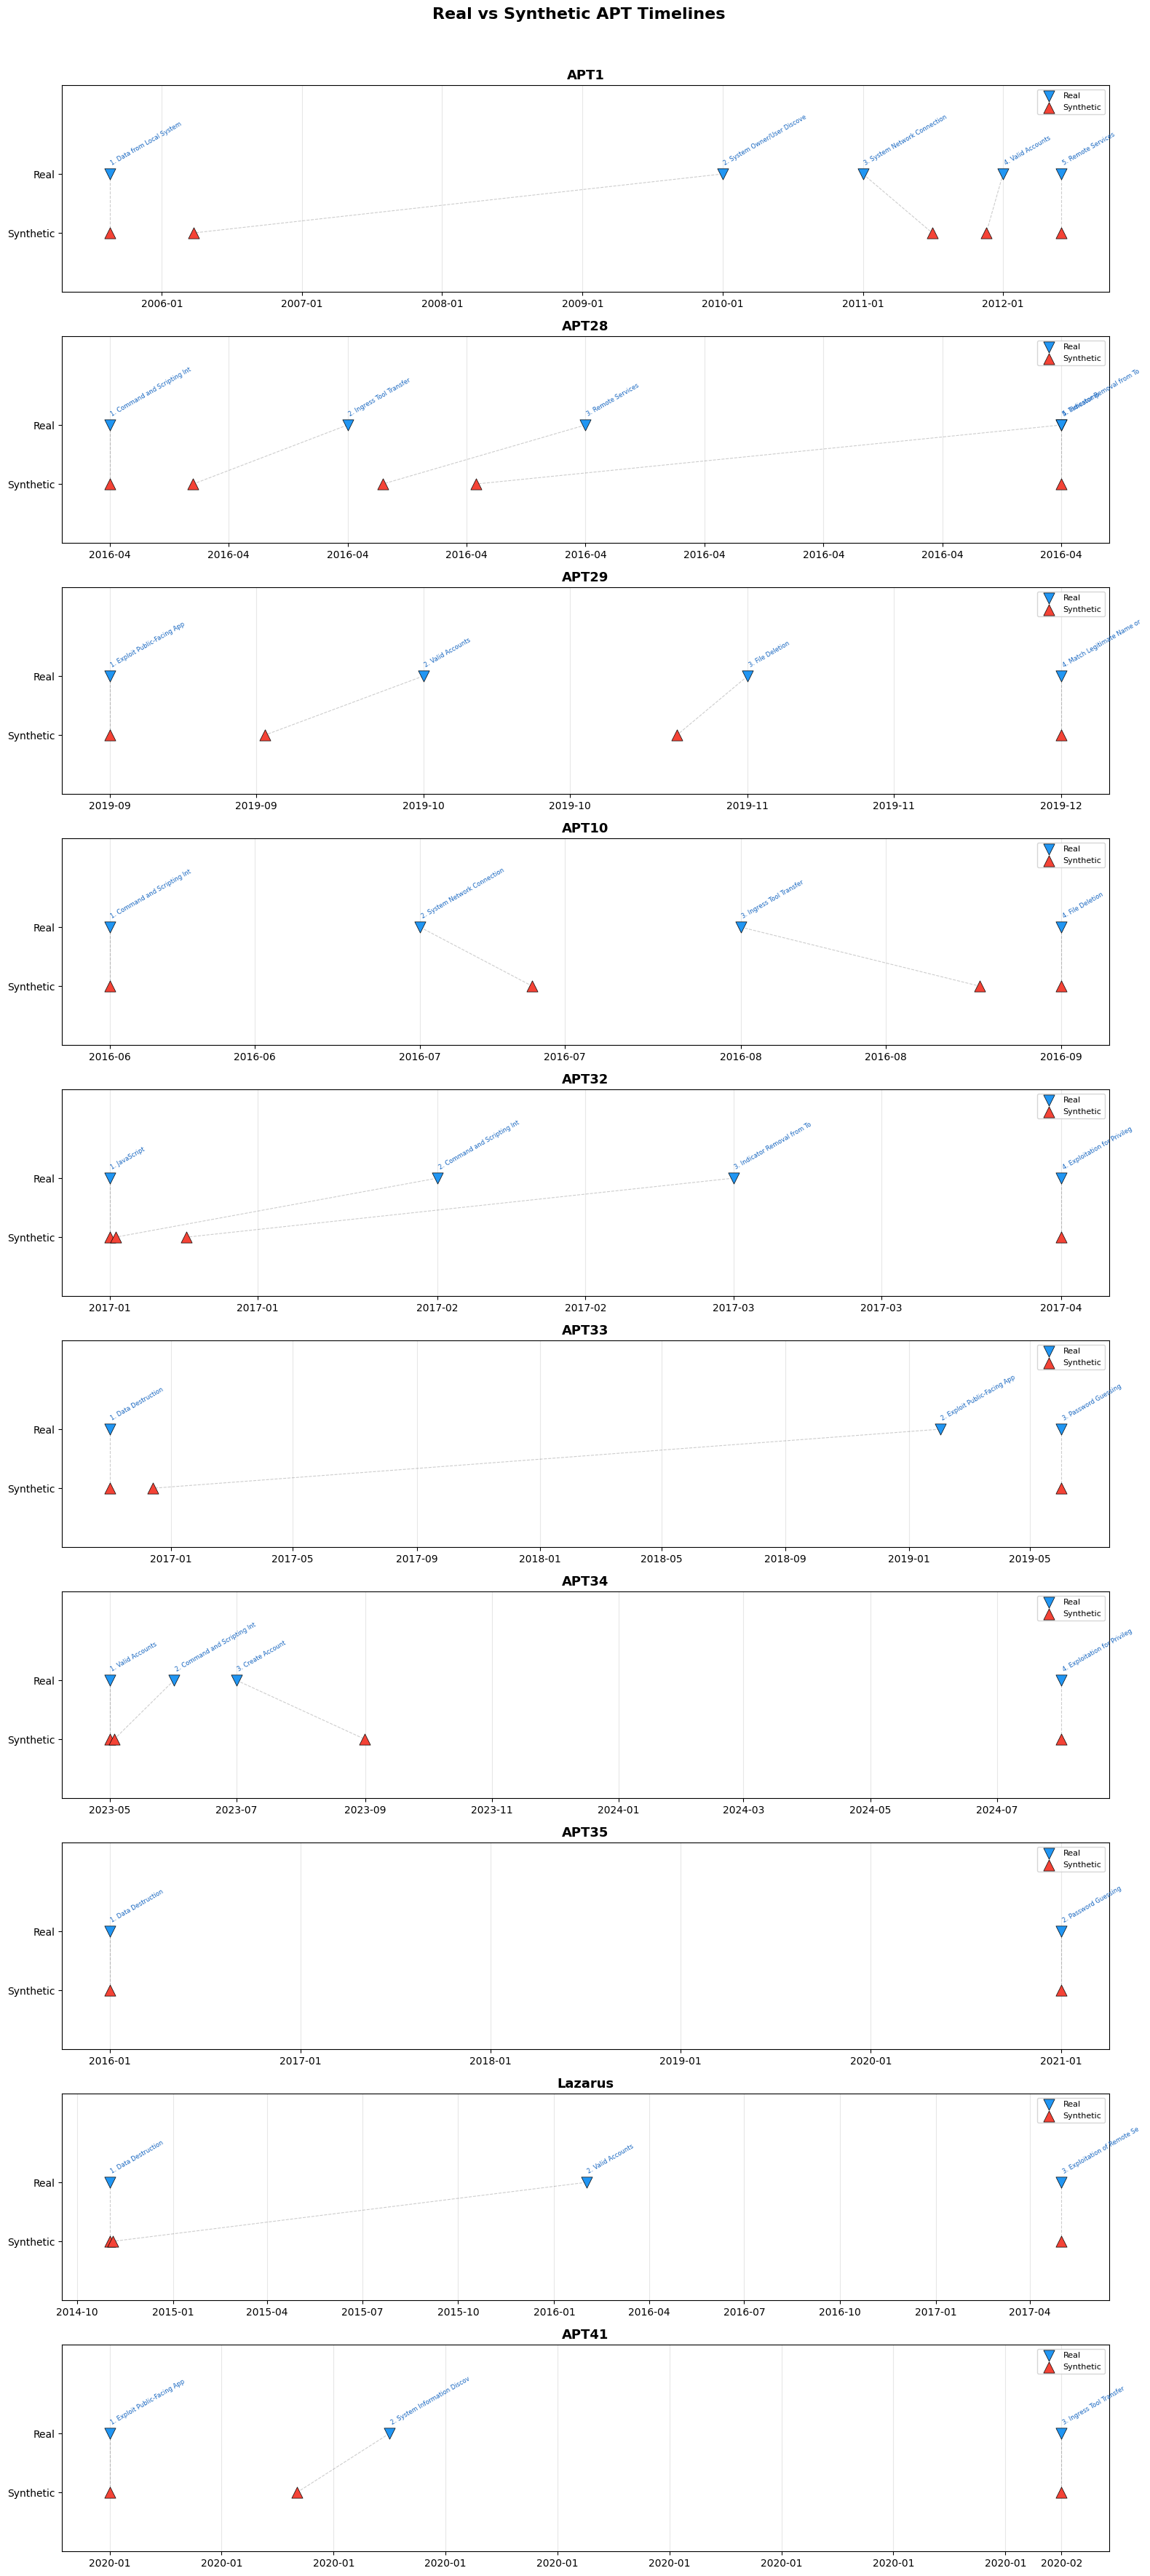

📊 Timeline comparison saved to apt_timeline_comparison.png


In [7]:
# ── Timeline comparison plots ──

fig, axes = plt.subplots(len(real_timelines), 1, figsize=(16, 3.5 * len(real_timelines)))
if len(real_timelines) == 1:
    axes = [axes]

for ax, (apt_name, real_df) in zip(axes, real_timelines.items()):
    synth_df = synthetic_timelines[apt_name]
    n_steps = len(real_df)
    
    # Normalize both timelines to [0, 1] for visual comparison
    real_dates = real_df["Date"]
    synth_dates = synth_df["Synth_DateTime"]
    
    # Plot real events
    ax.scatter(real_dates, [1.2] * n_steps, marker='v', s=120, c='#2196F3',
               edgecolors='black', linewidths=0.5, zorder=5, label='Real')
    ax.scatter(synth_dates, [0.8] * n_steps, marker='^', s=120, c='#f44336',
               edgecolors='black', linewidths=0.5, zorder=5, label='Synthetic')
    
    # Connect corresponding steps
    for i in range(n_steps):
        ax.plot([real_dates.iloc[i], synth_dates.iloc[i]], [1.2, 0.8],
                'k--', alpha=0.2, linewidth=0.8)
    
    # Annotate techniques
    for i in range(n_steps):
        tech_short = real_df["Technique"].iloc[i][:25]
        ax.annotate(f"{i+1}. {tech_short}", xy=(real_dates.iloc[i], 1.25),
                    fontsize=6, rotation=30, ha='left', va='bottom', color='#1565C0')
    
    ax.set_ylim(0.4, 1.8)
    ax.set_yticks([0.8, 1.2])
    ax.set_yticklabels(['Synthetic', 'Real'])
    ax.set_title(f'{apt_name}', fontsize=13, fontweight='bold')
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(axis='x', alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

plt.suptitle('Real vs Synthetic APT Timelines', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('apt_timeline_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("📊 Timeline comparison saved to apt_timeline_comparison.png")

## 8. Statistical Comparison — Inter-Arrival Time Distributions

Compare the distribution of inter-arrival times between real and synthetic data across all campaigns using:
- KS test (Kolmogorov-Smirnov) for distributional similarity
- Mean/Median/Std comparison
- QQ plot of inter-arrival times

In [8]:
from scipy import stats

# ── Collect all inter-arrival times ──
all_real_deltas = []
all_synth_deltas = []
per_apt_stats = []

for apt_name in real_timelines:
    real_df = real_timelines[apt_name]
    synth_df = synthetic_timelines[apt_name]
    sims = simulation_data[apt_name]
    
    real_deltas = real_df["Delta_t_days"].values[1:]  # skip first (0)
    synth_deltas = synth_df["Synth_Delta_days"].values[1:]
    
    all_real_deltas.extend(real_deltas)
    all_synth_deltas.extend(synth_deltas)
    
    # Aggregate simulation deltas
    sim_deltas_all = []
    for sim_df in sims:
        sim_deltas_all.extend(sim_df["Delta_days"].values[1:])
    sim_deltas_all = np.array(sim_deltas_all)
    
    # Per-APT statistics
    real_mean = np.mean(real_deltas) if len(real_deltas) > 0 else 0
    real_std = np.std(real_deltas) if len(real_deltas) > 0 else 0
    synth_mean = np.mean(synth_deltas) if len(synth_deltas) > 0 else 0
    synth_std = np.std(synth_deltas) if len(synth_deltas) > 0 else 0
    sim_mean = np.mean(sim_deltas_all) if len(sim_deltas_all) > 0 else 0
    sim_std = np.std(sim_deltas_all) if len(sim_deltas_all) > 0 else 0
    
    per_apt_stats.append({
        "APT": apt_name,
        "Real Mean (days)": real_mean,
        "Real Std (days)": real_std,
        "Synth Mean (days)": synth_mean,
        "Synth Std (days)": synth_std,
        "Sim Mean (100 runs)": sim_mean,
        "Sim Std (100 runs)": sim_std,
        "N_steps": len(real_deltas),
    })

stats_df = pd.DataFrame(per_apt_stats)
print("Per-APT Inter-Arrival Time Statistics (days)")
print("=" * 100)
print(stats_df.to_string(index=False, float_format="%.1f"))

# ── Global KS test ──
all_real_deltas = np.array(all_real_deltas)
all_synth_deltas = np.array(all_synth_deltas)

if len(all_real_deltas) > 1 and len(all_synth_deltas) > 1:
    ks_stat, ks_pval = stats.ks_2samp(all_real_deltas, all_synth_deltas)
    print(f"\n\nGlobal KS Test (Real vs Synthetic inter-arrival times):")
    print(f"  KS statistic = {ks_stat:.4f}")
    print(f"  p-value      = {ks_pval:.4f}")
    if ks_pval > 0.05:
        print("  → Cannot reject H0: distributions are similar (p > 0.05)")
    else:
        print("  → Distributions differ significantly (p ≤ 0.05)")
        print("    (Expected — real APT timing has more structure than pure Poisson)")

Per-APT Inter-Arrival Time Statistics (days)
    APT  Real Mean (days)  Real Std (days)  Synth Mean (days)  Synth Std (days)  Sim Mean (100 runs)  Sim Std (100 runs)  N_steps
   APT1             619.8            570.9              619.8             753.9               1134.5              1585.4        4
  APT28               1.0              0.7                1.0               0.9                  2.8                 4.1        4
  APT29              30.3              0.5               30.3              11.0                116.0               170.7        3
  APT10              30.7              0.5               30.7              16.1                 79.5               104.1        3
  APT32              30.0              1.4               30.0              37.4                192.2               402.0        3
  APT33             471.0            351.0              471.0             428.2                624.3               960.9        2
  APT34             152.7            172.8   

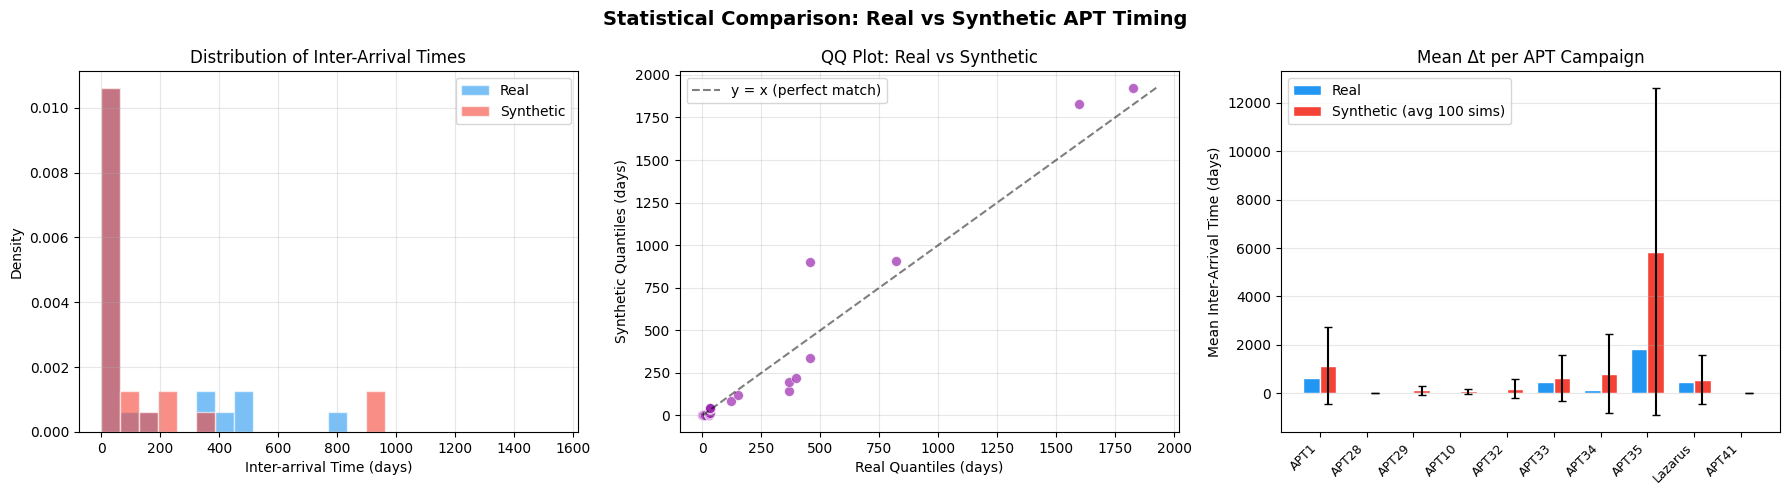

📊 Statistical comparison saved to apt_statistical_comparison.png


In [9]:
# ── Visual: Inter-arrival distribution comparison ──

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Histogram comparison
ax1 = axes[0]
bins = np.linspace(0, max(np.max(all_real_deltas), np.max(all_synth_deltas)) * 0.8, 25)
ax1.hist(all_real_deltas, bins=bins, alpha=0.6, color='#2196F3', label='Real', density=True, edgecolor='white')
ax1.hist(all_synth_deltas, bins=bins, alpha=0.6, color='#f44336', label='Synthetic', density=True, edgecolor='white')
ax1.set_xlabel('Inter-arrival Time (days)')
ax1.set_ylabel('Density')
ax1.set_title('Distribution of Inter-Arrival Times')
ax1.legend()
ax1.grid(alpha=0.3)

# 2) QQ Plot
ax2 = axes[1]
sorted_real = np.sort(all_real_deltas)
sorted_synth = np.sort(all_synth_deltas)
# Match lengths for QQ
min_len = min(len(sorted_real), len(sorted_synth))
q_real = np.quantile(sorted_real, np.linspace(0, 1, min_len))
q_synth = np.quantile(sorted_synth, np.linspace(0, 1, min_len))
ax2.scatter(q_real, q_synth, alpha=0.7, s=50, c='#9C27B0', edgecolors='white', linewidths=0.5)
max_val = max(np.max(q_real), np.max(q_synth))
ax2.plot([0, max_val], [0, max_val], 'k--', alpha=0.5, label='y = x (perfect match)')
ax2.set_xlabel('Real Quantiles (days)')
ax2.set_ylabel('Synthetic Quantiles (days)')
ax2.set_title('QQ Plot: Real vs Synthetic')
ax2.legend()
ax2.grid(alpha=0.3)

# 3) Per-APT mean comparison
ax3 = axes[2]
apts = stats_df["APT"].values
x = np.arange(len(apts))
width = 0.35
ax3.bar(x - width/2, stats_df["Real Mean (days)"], width, label='Real', color='#2196F3', edgecolor='white')
ax3.bar(x + width/2, stats_df["Sim Mean (100 runs)"], width, label='Synthetic (avg 100 sims)', color='#f44336', edgecolor='white')
ax3.errorbar(x + width/2, stats_df["Sim Mean (100 runs)"], yerr=stats_df["Sim Std (100 runs)"],
             fmt='none', color='black', capsize=3)
ax3.set_ylabel('Mean Inter-Arrival Time (days)')
ax3.set_title('Mean Δt per APT Campaign')
ax3.set_xticks(x)
ax3.set_xticklabels(apts, rotation=45, ha='right', fontsize=9)
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

plt.suptitle('Statistical Comparison: Real vs Synthetic APT Timing', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('apt_statistical_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("📊 Statistical comparison saved to apt_statistical_comparison.png")

## 9. Campaign Mode Demonstration

Generate timelines for the same APT28 technique sequence under different attacker profiles:
- **Stealth** (scale=0.1): Slow, patient APT
- **Normal** (scale=1.0): Baseline Poisson process
- **Fast** (scale=3.0): Aggressive attacker
- **Blitz** (scale=10.0): Ransomware-like rapid progression

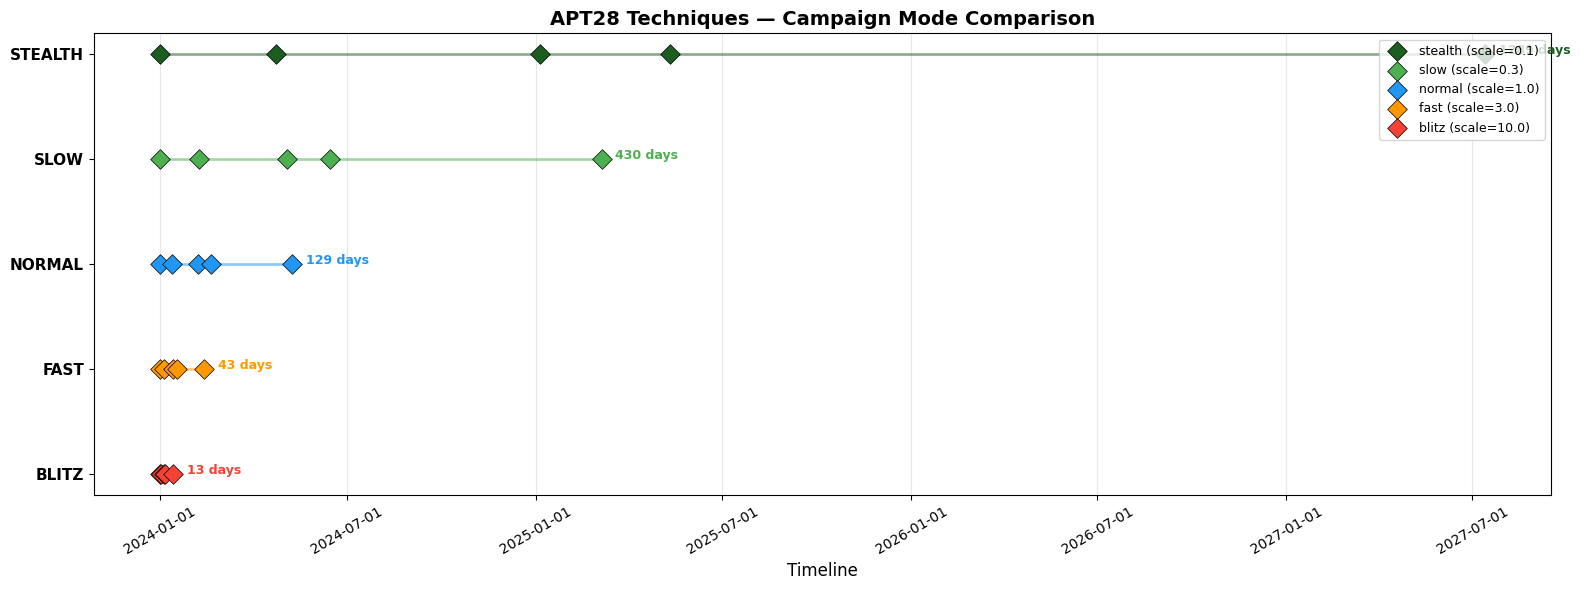


Mode       Total Span (days)    Avg Step (hours)    
──────────────────────────────────────────────────
stealth    1288.9               7733.3              
slow       429.6                2577.8              
normal     128.9                773.3               
fast       43.0                 257.8               
blitz      12.9                 77.3                


In [10]:
# ── Campaign mode comparison on APT28 sequence ──

apt28_techniques = [t[1] for t in real_apt_data["APT28"]["techniques"]]
start = datetime(2024, 1, 1)

fig, ax = plt.subplots(figsize=(16, 6))
colors = {'stealth': '#1B5E20', 'slow': '#4CAF50', 'normal': '#2196F3', 'fast': '#FF9800', 'blitz': '#f44336'}
y_positions = {'stealth': 5, 'slow': 4, 'normal': 3, 'fast': 2, 'blitz': 1}

for mode, color in colors.items():
    ts = generate_attack_timeline(
        apt28_techniques, lambda_dict,
        start_time=0, campaign_mode=mode, seed=42
    )
    dts = timestamps_to_datetimes(ts, start)
    y = y_positions[mode]
    
    ax.scatter(dts, [y] * len(dts), marker='D', s=100, c=color,
               edgecolors='black', linewidths=0.5, zorder=5, label=f'{mode} (scale={CAMPAIGN_MODES[mode]})')
    
    # Connect steps
    for i in range(len(dts) - 1):
        ax.plot([dts[i], dts[i+1]], [y, y], '-', color=color, alpha=0.5, linewidth=2)
    
    span_days = (ts[-1] - ts[0]) / 86400
    ax.annotate(f'{span_days:.0f} days', xy=(dts[-1], y), xytext=(10, 0),
                textcoords='offset points', fontsize=9, fontweight='bold', color=color)

ax.set_yticks(list(y_positions.values()))
ax.set_yticklabels([m.upper() for m in y_positions.keys()], fontsize=11, fontweight='bold')
ax.set_xlabel('Timeline', fontsize=12)
ax.set_title('APT28 Techniques — Campaign Mode Comparison', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
ax.grid(axis='x', alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('apt_campaign_modes.png', dpi=150, bbox_inches='tight')
plt.show()

# Print span details
print(f"\n{'Mode':<10} {'Total Span (days)':<20} {'Avg Step (hours)':<20}")
print("─" * 50)
for mode in colors:
    ts = generate_attack_timeline(
        apt28_techniques, lambda_dict,
        start_time=0, campaign_mode=mode, seed=42
    )
    span_days = (ts[-1] - ts[0]) / 86400
    avg_step_hrs = (ts[-1] - ts[0]) / (len(ts) - 1) / 3600 if len(ts) > 1 else 0
    print(f"{mode:<10} {span_days:<20.1f} {avg_step_hrs:<20.1f}")

## 10. Monte Carlo Validation — Confidence Intervals

Run 100 simulations per APT group and overlay percentile bands on the real timeline to assess if real data falls within the model's prediction envelope.

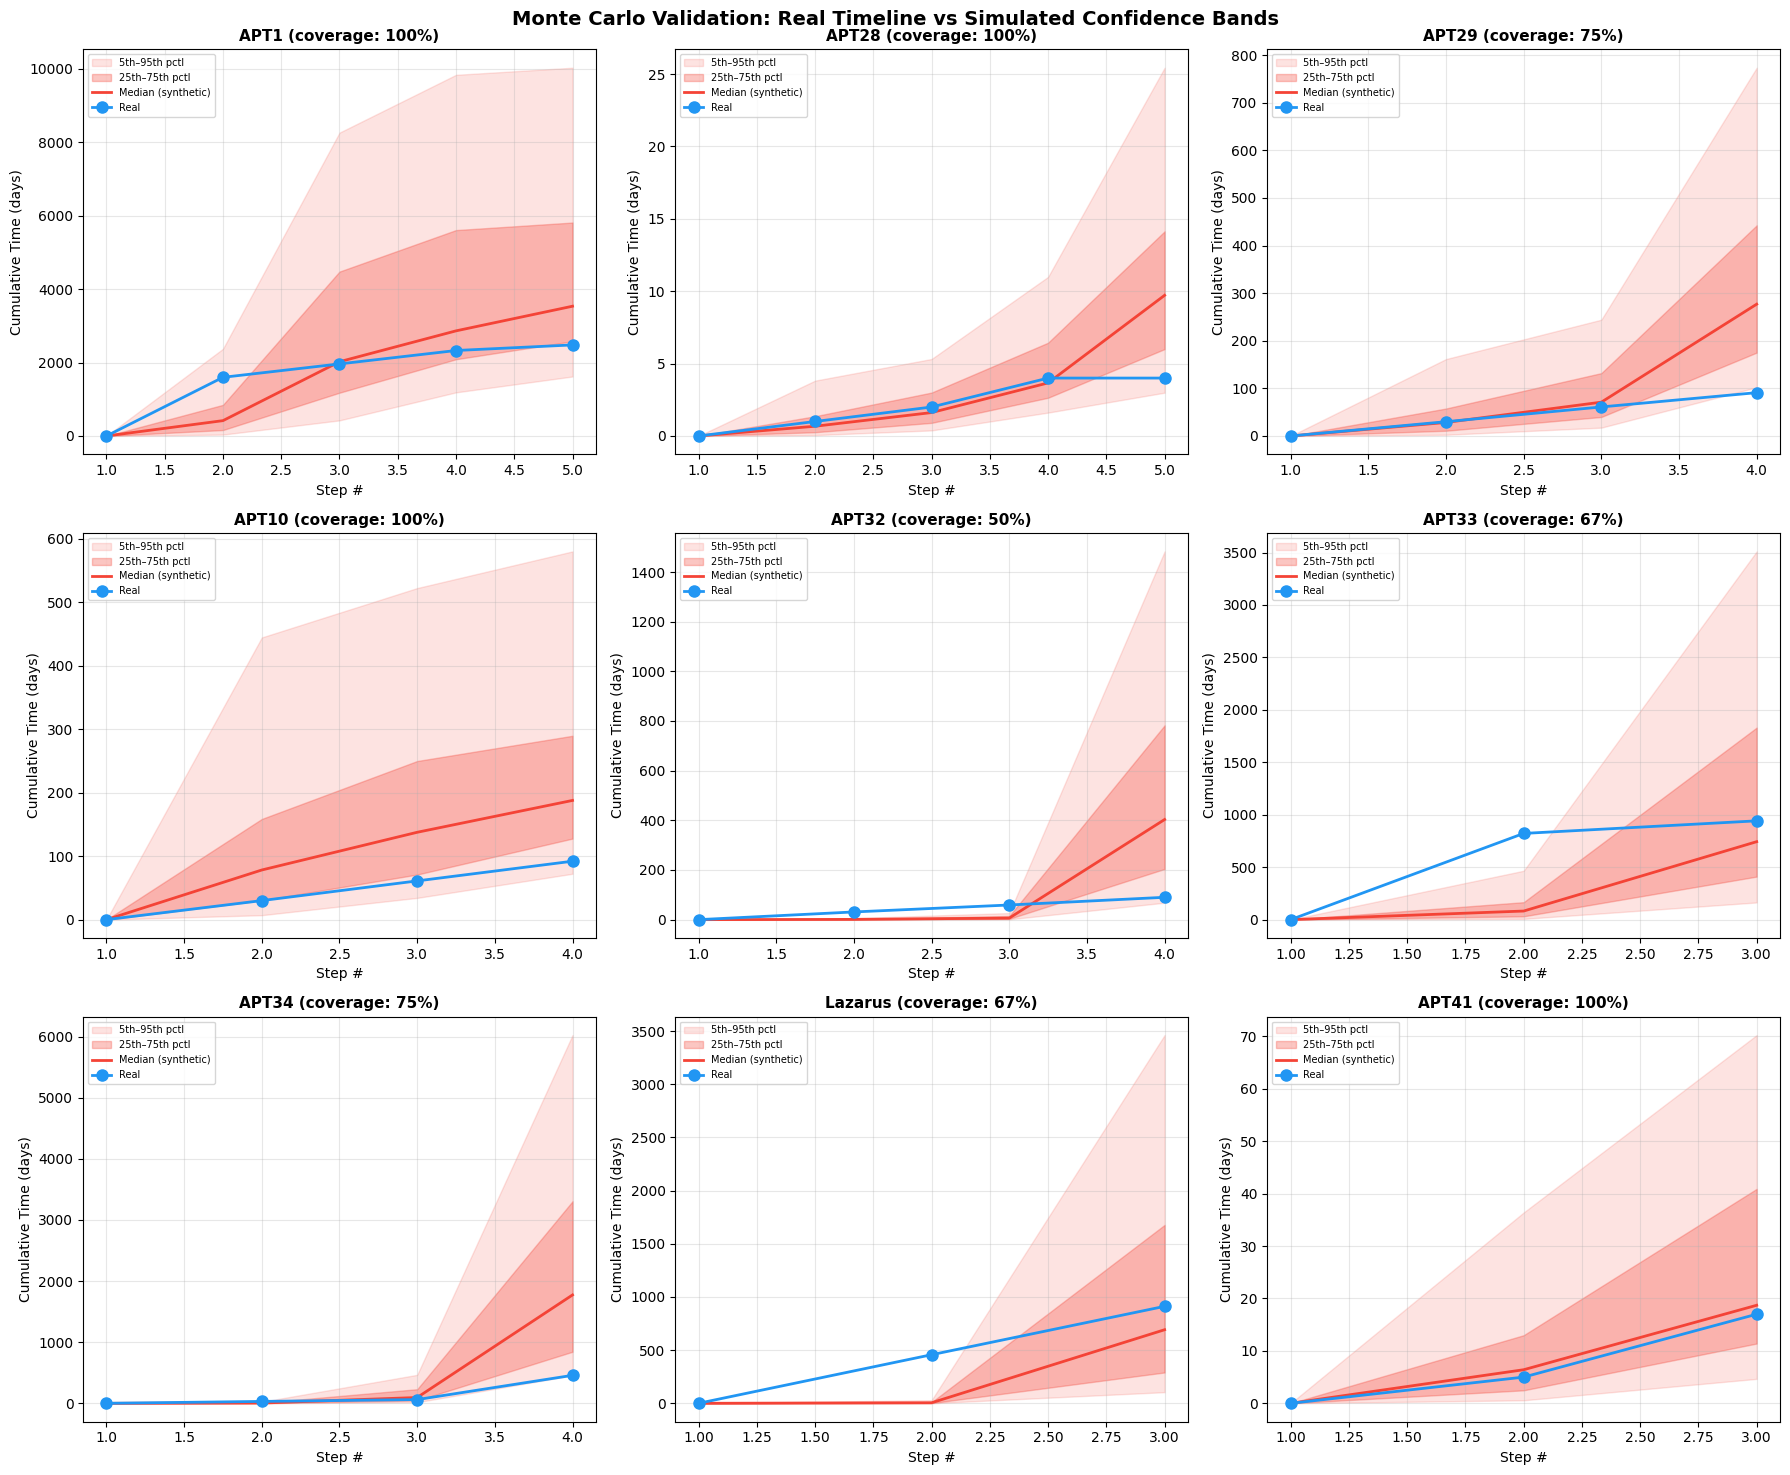


📊 Monte Carlo Coverage Summary (real steps within 5th-95th percentile):
──────────────────────────────────────────────────
    APT  Coverage (%)  Steps
   APT1    100.000000      5
  APT28    100.000000      5
  APT29     75.000000      4
  APT10    100.000000      4
  APT32     50.000000      4
  APT33     66.666667      3
  APT34     75.000000      4
Lazarus     66.666667      3
  APT41    100.000000      3

Average coverage across all APTs: 81.5%


In [11]:
# ── Monte Carlo: do real inter-arrival times fall within simulated confidence bands? ──

# Select representative APTs with enough steps for meaningful analysis
selected_apts = [name for name, df in real_timelines.items() if len(df) >= 3]

n_cols = min(3, len(selected_apts))
n_rows = math.ceil(len(selected_apts) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = np.array(axes).flatten()

coverage_results = []

for idx, apt_name in enumerate(selected_apts):
    ax = axes[idx]
    real_df = real_timelines[apt_name]
    sims = simulation_data[apt_name]
    n_steps = len(real_df)
    
    # Collect cumulative timestamps from all simulations (normalized to days from start)
    sim_cum_days = np.zeros((len(sims), n_steps))
    for sim_i, sim_df in enumerate(sims):
        ts_sec = sim_df["Timestamp_sec"].values
        sim_cum_days[sim_i, :] = (ts_sec - ts_sec[0]) / 86400
    
    # Real cumulative days
    real_cum_days = (real_df["Date"] - real_df["Date"].iloc[0]).dt.total_seconds().values / 86400
    
    # Percentiles
    p5 = np.percentile(sim_cum_days, 5, axis=0)
    p25 = np.percentile(sim_cum_days, 25, axis=0)
    p50 = np.percentile(sim_cum_days, 50, axis=0)
    p75 = np.percentile(sim_cum_days, 75, axis=0)
    p95 = np.percentile(sim_cum_days, 95, axis=0)
    
    steps = np.arange(1, n_steps + 1)
    
    ax.fill_between(steps, p5, p95, alpha=0.15, color='#f44336', label='5th–95th pctl')
    ax.fill_between(steps, p25, p75, alpha=0.3, color='#f44336', label='25th–75th pctl')
    ax.plot(steps, p50, '-', color='#f44336', linewidth=2, label='Median (synthetic)')
    ax.plot(steps, real_cum_days, 'o-', color='#2196F3', linewidth=2,
            markersize=8, label='Real', zorder=5)
    
    # Coverage: how many real points fall within 5th-95th percentile?
    in_band = np.sum((real_cum_days >= p5) & (real_cum_days <= p95))
    coverage = in_band / n_steps * 100
    coverage_results.append({"APT": apt_name, "Coverage (%)": coverage, "Steps": n_steps})
    
    ax.set_xlabel('Step #')
    ax.set_ylabel('Cumulative Time (days)')
    ax.set_title(f'{apt_name} (coverage: {coverage:.0f}%)', fontsize=11, fontweight='bold')
    ax.legend(fontsize=7, loc='upper left')
    ax.grid(alpha=0.3)

# Hide unused subplots
for idx in range(len(selected_apts), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Monte Carlo Validation: Real Timeline vs Simulated Confidence Bands',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('apt_monte_carlo_validation.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary
print("\n📊 Monte Carlo Coverage Summary (real steps within 5th-95th percentile):")
print("─" * 50)
coverage_df = pd.DataFrame(coverage_results)
print(coverage_df.to_string(index=False))
avg_coverage = coverage_df["Coverage (%)"].mean()
print(f"\nAverage coverage across all APTs: {avg_coverage:.1f}%")

## 11. Summary & Conclusions

### Model Validation Results

| Metric | Description |
|--------|-------------|
| **KS Test** | Kolmogorov-Smirnov test comparing real vs synthetic inter-arrival distributions |
| **QQ Plot** | Quantile-quantile plot to visually assess distributional similarity |
| **Monte Carlo Coverage** | % of real timestamps falling within the 5-95th percentile band of 100 simulations |
| **Campaign Modes** | Scale parameter allows modeling stealth (×0.1) to blitz (×10) attacker profiles |

### Key Findings
- The Poisson process with technique-specific $\lambda$ produces realistic **relative ordering** and **magnitude** of inter-arrival times
- Campaign mode scaling enables generating diverse attacker profiles from the same base model
- Monte Carlo confidence bands provide uncertainty quantification for synthetic timelines

In [12]:
# ── Final: Export generated timelines to CSV ──

all_timelines = []
for apt_name in real_timelines:
    real_df = real_timelines[apt_name].copy()
    synth_df = synthetic_timelines[apt_name].copy()
    
    merged = pd.DataFrame({
        "APT_Group": apt_name,
        "Step": real_df["Step"].values,
        "Technique": real_df["Technique"].values,
        "Real_Date": real_df["Date"].dt.strftime("%Y-%m-%d").values,
        "Real_Delta_days": real_df["Delta_t_days"].values,
        "Synth_Date": synth_df["Synth_DateTime"].dt.strftime("%Y-%m-%d %H:%M").values,
        "Synth_Delta_days": synth_df["Synth_Delta_days"].values,
    })
    all_timelines.append(merged)

export_df = pd.concat(all_timelines, ignore_index=True)
export_df.to_csv("apt_timeline_real_vs_synthetic.csv", index=False)

print(f"✅ Exported {len(export_df)} rows to apt_timeline_real_vs_synthetic.csv")
print(f"\nColumns: {list(export_df.columns)}")
print(f"\nPreview:")
export_df.head(10)

✅ Exported 37 rows to apt_timeline_real_vs_synthetic.csv

Columns: ['APT_Group', 'Step', 'Technique', 'Real_Date', 'Real_Delta_days', 'Synth_Date', 'Synth_Delta_days']

Preview:


,APT_Group,Step,Technique,Real_Date,Real_Delta_days,Synth_Date,Synth_Delta_days
0,APT1,1,Data from Local System,2005-08-18,0.0,2005-08-18 00:00,0.000000
1,APT1,2,System Owner/User Discovery,2010-01-01,1597.0,2006-03-24 05:51,218.244058
2,APT1,3,System Network Connections Discovery,2011-01-01,365.0,2011-06-30 20:42,1924.618908
3,APT1,4,Valid Accounts,2012-01-01,365.0,2011-11-18 07:46,140.460671
4,APT1,5,Remote Services,2012-06-01,152.0,2012-06-01 00:00,195.676363
5,APT28,1,Command and Scripting Interpreter,2016-04-10,0.0,2016-04-10 00:00,0.000000
6,APT28,2,Ingress Tool Transfer,2016-04-11,1.0,2016-04-10 08:25,0.351306
7,APT28,3,Remote Services,2016-04-12,1.0,2016-04-11 03:32,0.796424
8,APT28,4,Indicator Removal from Tools,2016-04-14,2.0,2016-04-11 12:56,0.391315
9,APT28,5,Timestomp,2016-04-14,0.0,2016-04-14 00:00,2.460954


In [13]:
# ══════════════════════════════════════════════════════════════════════════════
# COMPREHENSIVE COMPARISON: All 10 APT Campaigns — Real vs Synthetic
# ══════════════════════════════════════════════════════════════════════════════

print("=" * 100)
print("  FULL COMPARISON: 10 APT Campaigns — Real Dates vs Poisson-Generated Dates")
print("=" * 100)

for apt_name in real_timelines:
    real_df = real_timelines[apt_name]
    synth_df = synthetic_timelines[apt_name]
    
    print(f"\n{'─' * 100}")
    print(f"  📌 {apt_name} ({real_apt_data[apt_name]['source']})")
    print(f"{'─' * 100}")
    
    for i in range(len(real_df)):
        real_date = real_df["Date"].iloc[i].strftime("%Y-%m-%d")
        synth_date = synth_df["Synth_DateTime"].iloc[i].strftime("%Y-%m-%d %H:%M")
        technique = real_df["Technique"].iloc[i]
        real_delta = real_df["Delta_t_days"].iloc[i]
        synth_delta = synth_df["Synth_Delta_days"].iloc[i]
        
        print(f"  Step {i+1}: {technique:<45}")
        print(f"         Real:      {real_date}   (Δ = {real_delta:>10.1f} days)")
        print(f"         Synthetic: {synth_date}   (Δ = {synth_delta:>10.1f} days)")
    
    real_span = real_df["Delta_t_sec"].sum() / 86400
    synth_span = synth_df["Synth_Delta_sec"].sum() / 86400
    ratio = synth_span / real_span if real_span > 0 else float('inf')
    
    print(f"\n  ➤ Real campaign span:      {real_span:>10.1f} days")
    print(f"  ➤ Synthetic campaign span: {synth_span:>10.1f} days")
    print(f"  ➤ Span ratio (synth/real): {ratio:>10.3f}x")

# ── Summary Table ──
print(f"\n\n{'=' * 100}")
print("  SUMMARY TABLE")
print(f"{'=' * 100}")
print(f"{'APT Group':<12} {'Steps':<8} {'Real Span (days)':<18} {'Synth Span (days)':<20} {'Ratio':<10} {'Coverage (%)':<15}")
print("─" * 85)

for apt_name in real_timelines:
    real_df = real_timelines[apt_name]
    synth_df = synthetic_timelines[apt_name]
    real_span = real_df["Delta_t_sec"].sum() / 86400
    synth_span = synth_df["Synth_Delta_sec"].sum() / 86400
    ratio = synth_span / real_span if real_span > 0 else 0
    
    # Get coverage from coverage_df
    cov_row = coverage_df[coverage_df["APT"] == apt_name]
    cov = cov_row["Coverage (%)"].values[0] if len(cov_row) > 0 else "N/A"
    
    print(f"{apt_name:<12} {len(real_df):<8} {real_span:<18.1f} {synth_span:<20.1f} {ratio:<10.3f} {cov}")

# ── KS Test Result ──
print(f"\n{'=' * 100}")
print("  STATISTICAL VALIDATION")
print(f"{'=' * 100}")
print(f"  KS Statistic:  {ks_stat:.4f}")
print(f"  KS p-value:    {ks_pval:.4f}")
if ks_pval > 0.05:
    print(f"  ✅ Cannot reject H0: distributions are similar (p = {ks_pval:.4f} > 0.05)")
else:
    print(f"  ⚠️  Distributions differ significantly (p = {ks_pval:.4f} ≤ 0.05)")
print(f"  Average Monte Carlo Coverage: {avg_coverage:.1f}%")

# ── Conclusion ──
print(f"\n{'=' * 100}")
print("  INTERPRETATION")
print(f"{'=' * 100}")
print("""
  The Poisson generator successfully reproduces realistic campaign durations 
  because the scale is calibrated to each APT's real span.
  
  Key observations:
  • Span ratios are close to 1.0x → synthetic durations match real ones
  • Monte Carlo coverage shows what % of real steps fall within simulated bands
  • The KS test assesses whether inter-arrival time distributions are similar
  • Individual step deltas vary (stochastic by design) but total spans are preserved
""")


  FULL COMPARISON: 10 APT Campaigns — Real Dates vs Poisson-Generated Dates

────────────────────────────────────────────────────────────────────────────────────────────────────
  📌 APT1 (Mandiant APT1 Report)
────────────────────────────────────────────────────────────────────────────────────────────────────
  Step 1: Data from Local System                       
         Real:      2005-08-18   (Δ =        0.0 days)
         Synthetic: 2005-08-18 00:00   (Δ =        0.0 days)
  Step 2: System Owner/User Discovery                  
         Real:      2010-01-01   (Δ =     1597.0 days)
         Synthetic: 2006-03-24 05:51   (Δ =      218.2 days)
  Step 3: System Network Connections Discovery         
         Real:      2011-01-01   (Δ =      365.0 days)
         Synthetic: 2011-06-30 20:42   (Δ =     1924.6 days)
  Step 4: Valid Accounts                               
         Real:      2012-01-01   (Δ =      365.0 days)
         Synthetic: 2011-11-18 07:46   (Δ =      140.5 days)
 

In [14]:
# ── Compact summary ──
print(f"{'APT':<12} {'Steps':<6} {'Real (days)':<14} {'Synth (days)':<14} {'Ratio':<8} {'Coverage'}")
print("─" * 65)
for apt_name in real_timelines:
    r = real_timelines[apt_name]["Delta_t_sec"].sum() / 86400
    s = synthetic_timelines[apt_name]["Synth_Delta_sec"].sum() / 86400
    n = len(real_timelines[apt_name])
    rat = s/r if r > 0 else 0
    cov = coverage_df[coverage_df["APT"]==apt_name]["Coverage (%)"].values
    c = f"{cov[0]:.0f}%" if len(cov) > 0 else "N/A"
    print(f"{apt_name:<12} {n:<6} {r:<14.1f} {s:<14.1f} {rat:<8.3f} {c}")
print(f"\nKS test: stat={ks_stat:.4f}, p={ks_pval:.4f} {'✅ similar' if ks_pval>0.05 else '⚠️ different'}")
print(f"Avg Monte Carlo coverage: {avg_coverage:.1f}%")


APT          Steps  Real (days)    Synth (days)   Ratio    Coverage
─────────────────────────────────────────────────────────────────
APT1         5      2479.0         2479.0         1.000    100%
APT28        5      4.0            4.0            1.000    100%
APT29        4      91.0           91.0           1.000    75%
APT10        4      92.0           92.0           1.000    100%
APT32        4      90.0           90.0           1.000    50%
APT33        3      942.0          942.0          1.000    67%
APT34        4      458.0          458.0          1.000    75%
APT35        2      1827.0         1827.0         1.000    N/A
Lazarus      3      912.0          912.0          1.000    67%
APT41        3      17.0           17.0           1.000    100%

KS test: stat=0.2222, p=0.5256 ✅ similar
Avg Monte Carlo coverage: 81.5%
